# MaskFormer Inference Pipeline

Load a trained `GLCAnomalyMaskFormer` checkpoint, run inference on welding robot data, and produce dual-criterion anomaly verdicts.

**Pipeline:**
1. Load trained model checkpoint
2. Load mock CSV data → macro-windows
3. Preprocess inference data from per-cycle CSV files
4. Score batch both datasets + fit threshold via `MaskFormerThresholdCreator`
5. Apply threshold to inference data + evaluate (accuracy/F1)
6. Per-sensor heatmap analysis
7. Visualize heatmaps, anomaly scores, and localization
8. Summary report

In [1]:
# %% Imports
import sys
import csv
import json
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Add project root to path
project_root = Path.cwd().parent.parent.resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from app.anomaly_detection.models import (
    GLCAnomalyMaskFormer,
    MaskFormerModels,
)
# Local (Spark-free) 3-class inference pipeline
from app.anomaly_detection.inference.maskformer.local import (
    MaskFormerLocalPreResult,
    MaskFormerLocalThresholdCreator,
    MaskFormerLocalApplier,
)

print("All imports OK")
print(f"PyTorch {torch.__version__}, CUDA available: {torch.cuda.is_available()}")


All imports OK
PyTorch 2.12.0+cu130, CUDA available: True


## 1. Load Trained Model Checkpoint

Load the model state_dict + config saved by the training notebook.

In [2]:
# Path to trained checkpoint from Training-MaskFormer notebook
CKPT_DIR = project_root / "artifacts" / "maskformer_checkpoint_real"
MODEL_SLUG = "GLCAnomalyMaskFormer"
MODEL_FILE = f"model_{MODEL_SLUG}_best.pt"
META_FILE = f"metadata_{MODEL_SLUG}_best.json"
EXTRA_FILE = CKPT_DIR / "training_extra.json"

if not (CKPT_DIR / MODEL_FILE).exists():
    print(f"Checkpoint not found at {CKPT_DIR / MODEL_FILE}")
    print("Run the Training-MaskFormer notebook first to train and save a model.")
else:
    # Reconstruct model using BaseAnomalyDetectionModel.load_from_checkpoint
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = GLCAnomalyMaskFormer.load_from_checkpoint(
        checkpoint=str(CKPT_DIR),
        model_file=MODEL_FILE,
        metadata_file=META_FILE,
        device=str(device),
    )
    print(f"Model restored to {device}: {model.name}")
    print(f"  Params: {sum(p.numel() for p in model.parameters()):,}")

    # Load training extras (history, codebooks) if available
    extras = {}
    if EXTRA_FILE.exists():
        with open(EXTRA_FILE) as f:
            extras = json.load(f)
        print(f"  Training extras loaded: history ({len(extras.get('history',{}).get('loss',[]))} epochs), "
              f"robot_codebook ({len(extras.get('robot_codebook',{}))} codes)")


Model restored to cuda: GLCAnomalyMaskFormer
  Params: 857,479
  Training extras loaded: history (30 epochs), robot_codebook (1 codes)


## 2. Load and Preprocess CSV Data

Same macro-window preprocessing as the training notebook:
- Group by `(robot_code, start_time, program_number)`
- Sort by `serial_number`
- Pad or slice to `seq_len=240`
- Build robot/program codebooks

In [3]:
CSV_PATH = project_root / "data" / "mock_welding_robot_data.csv"
SENSOR_COLS = ["wire_feed_speed_m_min", "wire_temperature_c", "welding_current_a"]
SEQ_LEN = 240

print(f"Reading {CSV_PATH}...")
with open(CSV_PATH, "r") as f:
    reader = csv.DictReader(f)
    rows = list(reader)

print(f"Total rows: {len(rows):,}")

# Group rows by (robot_code, start_time, program_number)
groups = defaultdict(list)
for r in rows:
    key = (r["robot_code"], r["start_time"], r["program_number"])
    groups[key].append(r)

print(f"Total files (groups): {len(groups)}")

# Build codebooks
all_robot_codes = sorted(set(r["robot_code"] for r in rows))
all_program_nums = sorted(set(r["program_number"] for r in rows))
robot_to_idx = {code: i for i, code in enumerate(all_robot_codes)}
program_to_idx = {pn: i for i, pn in enumerate(all_program_nums)}

# Build file-windows
file_records = []
for key, group_rows in groups.items():
    group_rows.sort(key=lambda x: int(x["serial_number"]))
    file_arr = np.array(
        [[float(r[col]) for col in SENSOR_COLS] for r in group_rows],
        dtype=np.float32,
    )
    T = file_arr.shape[0]
    if T >= SEQ_LEN:
        window = file_arr[:SEQ_LEN, :].T  # [C, T]
    else:
        pad = np.zeros((SEQ_LEN - T, 3), dtype=np.float32)
        window = np.vstack([file_arr, pad]).T

    file_records.append({
        "key": key,
        "window": window,
        "robot_idx": robot_to_idx[key[0]],
        "program_idx": program_to_idx[key[2]],
        "robot_code": key[0],
        "program_number": int(key[2]),
        "start_time": key[1],
    })

print(f"Preprocessed {len(file_records)} file-windows")
print(f"Example: robot={file_records[0]['robot_code']}, "
      f"program={file_records[0]['program_number']}, "
      f"window shape={file_records[0]['window'].shape}")


Reading /home/trietlm/TED-Hackathon-Agent/data/mock_welding_robot_data.csv...
Total rows: 1,842,401
Total files (groups): 6000
Preprocessed 6000 file-windows
Example: robot=6, program=116, window shape=(3, 240)


## 3. Preprocess Inference Data into File-Windows

Same preprocessing as mock data but each inference CSV file is one cycle by `(robot_code, start_time, program_number)`.


In [4]:
# Build inference_file_records from per-cycle CSV files
# Reuse robot_to_idx/program_to_idx from mock data, extending with any new codes
import pandas as pd

INFERENCE_DIR = project_root / "data" / "inference"
csv_files = sorted(INFERENCE_DIR.glob("*.csv"))

inference_file_records = []
inference_labels = {}  # (robot_code, start_time, program_number) -> label

for fp in csv_files:
    # Parse label from filename
    if "_normal.csv" in fp.name:
        label = 0
    elif "_anomaly.csv" in fp.name:
        label = 1
    else:
        continue

    df = pd.read_csv(fp)
    # Each file is one cycle -> one group key
    rc = str(df["robot_code"].iloc[0])
    st = df["start_time"].iloc[0]
    pn = int(df["program_number"].iloc[0])
    key = (rc, st, pn)

    # Extend codebook if needed
    if rc not in robot_to_idx:
        robot_to_idx[rc] = len(robot_to_idx)
    if pn not in program_to_idx:
        program_to_idx[pn] = len(program_to_idx)

    # Sort by serial_number, extract sensor cols, pad/slice to SEQ_LEN
    df_sorted = df.sort_values("serial_number")
    file_arr = np.array(
        [[float(r) for r in df_sorted[col]] for col in SENSOR_COLS],
        dtype=np.float32,
    ).T  # [T, C]
    T = file_arr.shape[0]
    if T >= SEQ_LEN:
        window = file_arr[:SEQ_LEN, :].T  # [C, T]
    else:
        pad = np.zeros((SEQ_LEN - T, 3), dtype=np.float32)
        window = np.vstack([file_arr, pad]).T

    inference_file_records.append({
        "key": key,
        "window": window,
        "robot_idx": robot_to_idx[rc],
        "program_idx": program_to_idx[pn],
        "robot_code": rc,
        "program_number": pn,
        "start_time": st,
        "label": label,
    })
    inference_labels[key] = label

n_infer_normal = sum(1 for r in inference_file_records if r["label"] == 0)
n_infer_anomaly = sum(1 for r in inference_file_records if r["label"] == 1)
print(f"Preprocessed {len(inference_file_records)} inference file-windows")
print(f"  Normal files:  {n_infer_normal}")
print(f"  Anomaly files: {n_infer_anomaly}")
print(f"  Example: robot={inference_file_records[0]['robot_code']}, "
      f"program={inference_file_records[0]['program_number']}, "
      f"window shape={inference_file_records[0]['window'].shape}, "

      f"label={inference_file_records[0]['label']}")

Preprocessed 154 inference file-windows
  Normal files:  137
  Anomaly files: 17
  Example: robot=6, program=116, window shape=(3, 240), label=0


## 4. Score Batch Both Datasets & Fit Threshold

`MaskFormerLocalPreResult.score_batch()` on mock + inference → `MaskFormerLocalThresholdCreator.fit()` → visualize → manual threshold → `MaskFormerLocalApplier.apply()` on mock.

The `score_batch` accepts `list[dict]` records with windows + serials, simulates the macro-window accumulation logic that the Spark version would use, and returns per-file pre-results with per-sensor heatmaps.

Mock pre-result records:      6000
  Example windows shape: (1, 3, 240)
Inference pre-result records: 154
  Example windows shape: (1, 3, 240)

Mock scored files:       6000
Inference scored files:  154
Auto-fitted threshold (P95 via ThresholdCreator): 0.344526


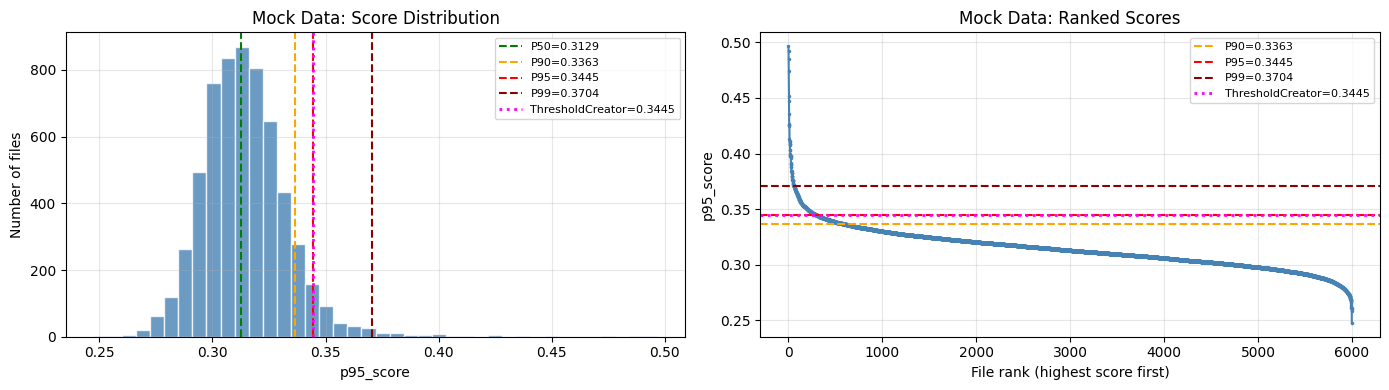

Percentile reference (mock scores):
  P 50.0: 0.312858
  P 75.0: 0.324648
  P 90.0: 0.336340
  P 95.0: 0.344526
  P 99.0: 0.370402
  P 99.5: 0.387650
  P 99.9: 0.435896

Chosen threshold: 0.344526
Files flagged at this threshold: 300 / 6000 (5.0%)

Mock verdict distribution:
  Normal files:    5700 (95.0%)
  Anomalous files: 300 (5.0%)

Top-5 most anomalous (mock):
  #1: robot=6, prog=116, score=0.496588 ⚠️
  #2: robot=6, prog=116, score=0.492298 ⚠️
  #3: robot=6, prog=116, score=0.485350 ⚠️
  #4: robot=6, prog=116, score=0.474483 ⚠️
  #5: robot=6, prog=116, score=0.451833 ⚠️


In [ ]:
# ── Helper: build macro-window records for one dataset ──
def build_pre_result_records(file_records_list, seq_len=SEQ_LEN, patch_stride=16):
    records = []
    for rec in file_records_list:
        window = rec["window"]  # [C, T]
        _, T = window.shape
        windows_list = []
        serials_list = []
        for w in range(0, min(T - seq_len + 1, 3) * patch_stride, patch_stride):
            if w + seq_len <= T:
                windows_list.append(window[:, w:w+seq_len])
                serials_list.append(w)
        if not windows_list:
            windows_list.append(window[:, :seq_len])
            serials_list.append(0)
        records.append({
            "robot_code": rec["robot_code"],
            "program_number": rec["program_number"],
            "start_time": rec["start_time"],
            "windows": np.stack(windows_list),  # [N, C, W]
            "serials": np.array(serials_list, dtype=np.int64),
        })
    return records

# ── Phase 2: Build macro-window records & score both datasets ──
mock_pre_result_records = build_pre_result_records(file_records)
infer_pre_result_records = build_pre_result_records(inference_file_records)

print(f"Mock pre-result records:      {len(mock_pre_result_records)}")
print(f"  Example windows shape: {mock_pre_result_records[0]['windows'].shape}")
print(f"Inference pre-result records: {len(infer_pre_result_records)}")
print(f"  Example windows shape: {infer_pre_result_records[0]['windows'].shape}")

# Score batch on both datasets
metadata = model.get_metadata()
state_dict = model.state_dict()
pre_result_engine = MaskFormerLocalPreResult(
    model_version=MaskFormerModels.GLC_ANOMALY_MASKFORMER,
    metadata=metadata,
    state_dict=state_dict,
    quantile=0.9,
    k_skip=0,
    fast=True,
    device=str(device),
)
mock_pre_scores = pre_result_engine.score_batch(mock_pre_result_records)
infer_pre_scores = pre_result_engine.score_batch(infer_pre_result_records)

print(f"\nMock scored files:       {len(mock_pre_scores)}")
print(f"Inference scored files:  {len(infer_pre_scores)}")

# ── Phase 3: Auto-fit via ThresholdCreator, then visualize & let user override ──
threshold_creator = MaskFormerLocalThresholdCreator(quantile=0.9)
threshold_creator.fit_from_pre_results(mock_pre_scores)
auto_threshold = threshold_creator.threshold
print(f"Auto-fitted threshold (P95 via ThresholdCreator): {auto_threshold:.6f}")

mock_scores = np.array([float(r["p95_score"]) for r in mock_pre_scores])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 3a. Histogram with percentile lines
ax = axes[0]
ax.hist(mock_scores, bins=40, color="steelblue", edgecolor="white", alpha=0.8)
for p, label, color in [(50, "P50", "green"), (90, "P90", "orange"),
                          (95, "P95", "red"), (99, "P99", "darkred")]:
    val = np.percentile(mock_scores, p)
    ax.axvline(val, color=color, linestyle="--", label=f"{label}={val:.4f}")
ax.axvline(auto_threshold, color="magenta", linestyle=":", linewidth=2,
           label=f"ThresholdCreator={auto_threshold:.4f}")
ax.set_xlabel("p95_score")
ax.set_ylabel("Number of files")
ax.set_title("Mock Data: Score Distribution")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# 3b. Ranked score curve
ax = axes[1]
sorted_s = np.sort(mock_scores)[::-1]
ax.plot(sorted_s, marker=".", markersize=3, color="steelblue")
for p, label, color in [(90, "P90", "orange"), (95, "P95", "red"), (99, "P99", "darkred")]:
    val = np.percentile(mock_scores, p)
    ax.axhline(val, color=color, linestyle="--", label=f"{label}={val:.4f}")
ax.axhline(auto_threshold, color="magenta", linestyle=":", linewidth=2,
           label=f"ThresholdCreator={auto_threshold:.4f}")
ax.set_xlabel("File rank (highest score first)")
ax.set_ylabel("p95_score")
ax.set_title("Mock Data: Ranked Scores")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print percentiles for reference
print("Percentile reference (mock scores):")
for p in [50, 75, 90, 95, 99, 99.5, 99.9]:
    print(f"  P{p:5.1f}: {np.percentile(mock_scores, p):.6f}")

# raw = input(f"Enter threshold value (auto={auto_threshold:.6f}): ").strip()
raw = None
user_threshold = float(raw) if raw else auto_threshold
print(f"\nChosen threshold: {user_threshold:.6f}")
n_flagged = int((mock_scores > user_threshold).sum())
print(f"Files flagged at this threshold: {n_flagged} / {len(mock_scores)} "
      f"({100*n_flagged/len(mock_scores):.1f}%)")

# Apply threshold to mock data
applier = MaskFormerLocalApplier(
    threshold_config={"global_threshold": user_threshold},
    quantile=0.9,
)
mock_applied = applier.apply(mock_pre_scores)

# ── Backward-compatible aliases for downstream cells ──
global_threshold = user_threshold
applied_results = mock_applied
n_normal = sum(1 for r in mock_applied if not r["is_file_anomaly"])
n_anomaly = sum(1 for r in mock_applied if r["is_file_anomaly"])
sorted_results = sorted(mock_applied, key=lambda r: float(r["p95_score"]), reverse=True)



print(f"\nMock verdict distribution:")
print(f"  Normal files:    {n_normal} ({100*n_normal/len(mock_applied):.1f}%)")
print(f"  Anomalous files: {n_anomaly} ({100*n_anomaly/len(mock_applied):.1f}%)")

print(f"\nTop-5 most anomalous (mock):")
for i, r in enumerate(sorted_results[:5]):
    print(f"  #{i+1}: robot={r['robot_code']}, prog={r['program_number']}, "
          f"score={r['p95_score']:.6f} {'⚠️' if r['is_file_anomaly'] else '✓'}")

## 5. Apply Threshold to Inference & Evaluate

Use the manually-chosen threshold on inference data, then compute accuracy / F1 against ground-truth labels.


In [6]:
# Apply threshold to inference data
infer_applied = applier.apply(infer_pre_scores)

# Merge ground-truth labels from inference_file_records
label_map = {r["key"]: r["label"] for r in inference_file_records}
y_true = []
y_pred = []
for r in infer_applied:
    key = (r["robot_code"], str(r["start_time"]), r["program_number"])
    y_true.append(label_map.get(key, -1))
    y_pred.append(1 if r["is_file_anomaly"] else 0)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Compute metrics
n_correct = (y_true == y_pred).sum()
accuracy = n_correct / len(y_true)

tp = ((y_true == 1) & (y_pred == 1)).sum()
fp = ((y_true == 0) & (y_pred == 1)).sum()
fn = ((y_true == 1) & (y_pred == 0)).sum()
tn = ((y_true == 0) & (y_pred == 0)).sum()

precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

print("=" * 60)
print("INFERENCE DATA EVALUATION")
print("=" * 60)
print(f"  Threshold:               {user_threshold:.6f}")
print(f"  Total inference files:   {len(infer_applied)}")
print(f"  Ground-truth normal:     {(y_true == 0).sum()}")
print(f"  Ground-truth anomaly:    {(y_true == 1).sum()}")
print(f"  Predicted normal:        {(y_pred == 0).sum()}")
print(f"  Predicted anomaly:       {(y_pred == 1).sum()}")
print()
print(f"  Accuracy:  {accuracy:.4f}  ({n_correct}/{len(y_true)})")
print(f"  Precision: {precision:.4f}")
print(f"  Recall:    {recall:.4f}")
print(f"  F1 Score:  {f1:.4f}")
print()
print("Confusion Matrix:")
print(f"              Pred Normal   Pred Anomaly")
print(f"  True Normal   {tn:>4d}           {fp:>4d}")
print(f"  True Anomaly  {fn:>4d}           {tp:>4d}")
print()

# Show misclassified files
print("Misclassified files:")
misclassified = [r for r, yt, yp in zip(infer_applied, y_true, y_pred) if yt != yp]
for r in misclassified[:10]:
    key = (r["robot_code"], str(r["start_time"]), r["program_number"])
    gt = label_map.get(key, -1)
    print(f"  robot={r['robot_code']}, prog={r['program_number']}, "
          f"score={r['p95_score']:.6f}, pred={'anomaly' if r['is_file_anomaly'] else 'normal'}, "
          f"ground_truth={'anomaly' if gt else 'normal'}")
if len(misclassified) > 10:
    print(f"  ... and {len(misclassified) - 10} more")
print("=" * 60)


INFERENCE DATA EVALUATION
  Threshold:               0.344526
  Total inference files:   154
  Ground-truth normal:     137
  Ground-truth anomaly:    17
  Predicted normal:        143
  Predicted anomaly:       11

  Accuracy:  0.8701  (134/154)
  Precision: 0.3636
  Recall:    0.2353
  F1 Score:  0.2857

Confusion Matrix:
              Pred Normal   Pred Anomaly
  True Normal    130              7
  True Anomaly    13              4

Misclassified files:
  robot=6, prog=116, score=0.358233, pred=anomaly, ground_truth=normal
  robot=6, prog=116, score=0.374810, pred=anomaly, ground_truth=normal
  robot=6, prog=116, score=0.299649, pred=normal, ground_truth=anomaly
  robot=6, prog=116, score=0.322633, pred=normal, ground_truth=anomaly
  robot=6, prog=116, score=0.321186, pred=normal, ground_truth=anomaly
  robot=6, prog=116, score=0.315022, pred=normal, ground_truth=anomaly
  robot=6, prog=116, score=0.346014, pred=anomaly, ground_truth=normal
  robot=6, prog=116, score=0.326006, pred=

## 6. Per-Sensor Heatmap Analysis

Compute per-sensor heatmaps and p95 scores as `MaskFormerPreResult` would, then apply per-sensor thresholds.

In [8]:
mock_applied[0].keys()

dict_keys(['robot_code', 'program_number', 'start_time', 'is_file_anomaly', 'p95_score', 'heatmap_wire_feed_speed', 'is_anomaly_wire_feed_speed', 'heatmap_wire_temperature', 'is_anomaly_wire_temperature', 'heatmap_welding_current', 'is_anomaly_welding_current'])

In [ ]:
SENSOR_NAMES = ["wire_feed_speed", "wire_temperature", "welding_current"]

# Applier already computed per-sensor flags — build combined heatmap + sensor_verdicts
HEATMAP_KEYS = ["heatmap_wire_feed_speed", "heatmap_wire_temperature", "heatmap_welding_current"]
ANOMALY_KEYS = ["is_anomaly_wire_feed_speed", "is_anomaly_wire_temperature", "is_anomaly_welding_current"]

# P (num patches) from first file
P = len(mock_applied[0][HEATMAP_KEYS[0]])

for r in mock_applied:
    # Build combined heatmap [3, P] from per-sensor 1D arrays
    r["sensor_verdicts"] = {}
    hm_rows = []
    for sn, hk, ak in zip(SENSOR_NAMES, HEATMAP_KEYS, ANOMALY_KEYS):
        hm_rows.append(r[hk])
        r["sensor_verdicts"][sn] = bool(r[ak])
    r["heatmap"] = np.stack(hm_rows)  # [3, P]

# Per-sensor max heatmap stats
per_sensor_max = {s: [] for s in SENSOR_NAMES}
for r in mock_applied:
    for si, sn in enumerate(SENSOR_NAMES):
        per_sensor_max[sn].append(r["heatmap"][si].max())

print("Per-sensor max heatmap statistics:")
for sn in SENSOR_NAMES:
    vals = np.array(per_sensor_max[sn])
    print(f"  {sn}: mean={vals.mean():.4f}, max={vals.max():.4f}, P95={np.percentile(vals, 95):.4f}")

# Per-sensor thresholds (P95) — for reporting only, applier uses its own
sensor_thresholds = {
    sn: float(np.percentile(per_sensor_max[sn], 95))
    for sn in SENSOR_NAMES
}
print(f"\nPer-sensor P95 thresholds:")
for sn, th in sensor_thresholds.items():
    print(f"  {sn}: {th:.6f}")

# Recompute n_normal/n_anomaly from applier's is_file_anomaly
n_normal = sum(1 for r in mock_applied if not r["is_file_anomaly"])
n_anomaly = sum(1 for r in mock_applied if r["is_file_anomaly"])
sorted_results = sorted(mock_applied, key=lambda r: float(r["p95_score"]), reverse=True)

print(f"\nMock verdict distribution (per-sensor: file anomaly if ANY sensor flagged):")
print(f"  Normal files:    {n_normal} ({100*n_normal/len(mock_applied):.1f}%)")
print(f"  Anomalous files: {n_anomaly} ({100*n_anomaly/len(mock_applied):.1f}%)")

# Show sample verdicts
print(f"\nSample verdicts (first 10 files):")
print(f"{'robot':>6} {'prog':>5} {'score':>10} {'file?':>6} ", end="")
for sn in SENSOR_NAMES:
    print(f"{sn[:8]:>8}", end="")
print()
for r in mock_applied[:10]:
    print(f"{r['robot_code']:>6} {r['program_number']:>5} {r['p95_score']:>10.6f} "
          f"{'⚠️' if r['is_file_anomaly'] else '✓':>6} ", end="")
    for sn in SENSOR_NAMES:
        print(f"{'⚠️' if r['sensor_verdicts'][sn] else '✓':>8}", end="")
    print()


KeyError: 'heatmap'

## 7. Visualize Results

### 7a. Anomaly Score Distribution

/tmp/ipykernel_851506/2809486054.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot([scores[~is_anom], scores[is_anom]], labels=["Normal", "Anomaly"],


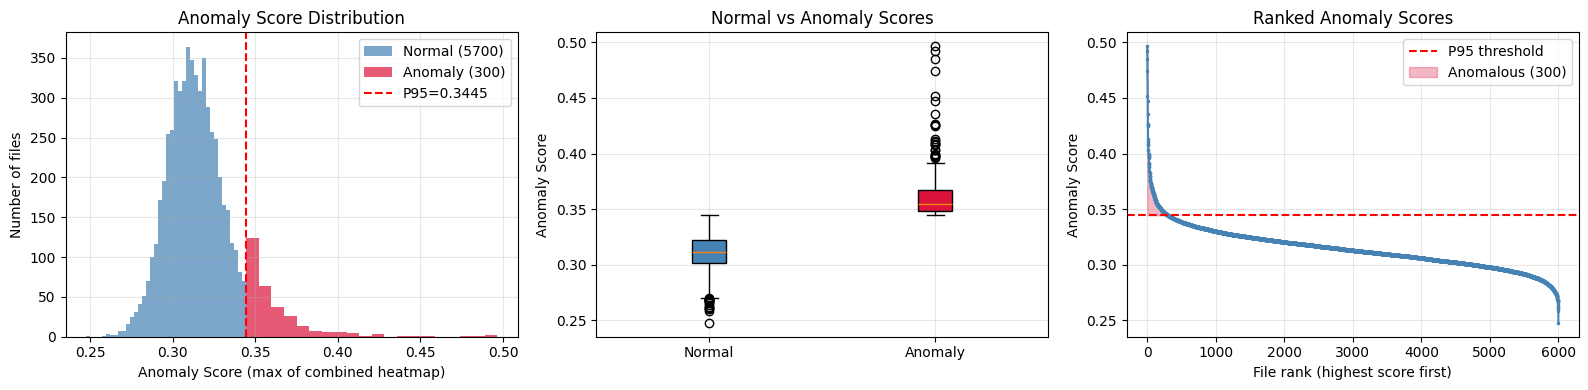

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

scores = np.array([r["p95_score"] for r in mock_applied])
is_anom = np.array([r["is_file_anomaly"] for r in mock_applied])

# Histogram
ax = axes[0]
ax.hist(scores[~is_anom], bins=40, alpha=0.7, label=f"Normal ({n_normal})", color="steelblue")
ax.hist(scores[is_anom], bins=20, alpha=0.7, label=f"Anomaly ({n_anomaly})", color="crimson")
ax.axvline(global_threshold, color="red", linestyle="--", label=f"P95={global_threshold:.4f}")
ax.set_xlabel("Anomaly Score (max of combined heatmap)")
ax.set_ylabel("Number of files")
ax.set_title("Anomaly Score Distribution")
ax.legend()
ax.grid(True, alpha=0.3)

# Box plot
ax = axes[1]
bp = ax.boxplot([scores[~is_anom], scores[is_anom]], labels=["Normal", "Anomaly"],
                patch_artist=True)
bp["boxes"][0].set_facecolor("steelblue")
bp["boxes"][1].set_facecolor("crimson")
ax.set_ylabel("Anomaly Score")
ax.set_title("Normal vs Anomaly Scores")
ax.grid(True, alpha=0.3)

# Score rank plot
ax = axes[2]
sorted_scores = np.sort(scores)[::-1]
ax.plot(sorted_scores, marker=".", markersize=3, color="steelblue")
ax.axhline(global_threshold, color="red", linestyle="--", label=f"P95 threshold")
ax.fill_between(range(len(sorted_scores)), sorted_scores, global_threshold,
                 where=(sorted_scores > global_threshold), color="crimson", alpha=0.3,
                 label=f"Anomalous ({n_anomaly})")
ax.set_xlabel("File rank (highest score first)")
ax.set_ylabel("Anomaly Score")
ax.set_title("Ranked Anomaly Scores")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### 7b. Dual Heatmap Visualization (Association × Reconstruction)

For the top anomalous file, visualize how the two signals combine:

In [ ]:
# Pick the most anomalous file
top = sorted_results[0]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
P = top["heatmap"].shape[1]            # number of patches
patch_labels = [f"p{i}" for i in range(P)]

# Show per-sensor heatmaps (the applier produces combined heatmaps by sensor)
for ax, sn, si in zip(axes, SENSOR_NAMES, range(3)):
    hm_1d = top[f"heatmap_{sn}"]       # [P]
    hm_2d = hm_1d.reshape(1, -1)       # [1, P] for imshow
    im = ax.imshow(hm_2d, aspect="auto", cmap="Reds", vmin=0)
    ax.set_xticks(range(P))
    ax.set_xticklabels(patch_labels, fontsize=8)
    ax.set_yticks([0])
    ax.set_yticklabels([sn], fontsize=9)
    ax.set_title(f"{sn}\n(is_anomaly={top[f'is_anomaly_{sn}']})", fontsize=10)
    plt.colorbar(im, ax=ax, shrink=0.8)

plt.suptitle(f"Top Anomaly: robot={top['robot_code']}, prog={top['program_number']}, "
             f"score={top['p95_score']:.4f}",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### 7c. Counterfactual Visualization

Show what the model expected vs what actually happened on the most anomalous sensor-patch:

In [ ]:
# Find the most anomalous (sensor, patch) position in the top file
combined = top["heatmap"]  # [3, P]
P = combined.shape[1]
max_si, max_pi = np.unravel_index(combined.argmax(), combined.shape)
print(f"Peak anomaly at sensor={SENSOR_NAMES[max_si]}, patch={max_pi}")

# Get the original raw window for this file
top_key = (top["robot_code"], str(top["start_time"]), top["program_number"])
top_rec = next(r for r in file_records if r["key"] == top_key)
raw_window = top_rec["window"]  # [3, 240]

# Compute patch time range
patch_size = model.patch_size   # 32
patch_stride = model.patch_stride  # 16
t_start = max_pi * patch_stride
t_end = min(t_start + patch_size, SEQ_LEN)

# Extract actual and use model to get predicted (counterfactual) patch
inp_t = torch.from_numpy(raw_window).unsqueeze(0).to(device)
robot_t = torch.tensor([top_rec["robot_idx"]], dtype=torch.long, device=device)
prog_t = torch.tensor([top_rec["program_idx"]], dtype=torch.long, device=device)

with torch.no_grad():
    tokens, local_patches = model._tokenize(inp_t, robot_t, prog_t)
    # Mask the single most anomalous token
    mask_single = torch.zeros(1, tokens.shape[1], dtype=torch.bool, device=device)
    token_idx = max_si * P + max_pi
    mask_single[0, token_idx] = True
    tokens_masked = model.mask_token(tokens, mask_single)
    out_t = model.transformer.forward_with_detach_mode(tokens_masked, detach="none")
    predicted_patch = model.decoder(out_t["out"])[0, token_idx].cpu().numpy()  # [32]

# Actual local patch (RevIN'd)
actual_patch = local_patches[0, token_idx].cpu().numpy()  # [32]

fig, ax = plt.subplots(figsize=(12, 4))
time_axis = np.arange(t_start, t_end)
ax.plot(time_axis, actual_patch, label="Actual (local RevIN'd)", color="crimson", linewidth=2)
ax.plot(time_axis, predicted_patch, label="Model prediction (counterfactual normal)", color="steelblue", linewidth=2, linestyle="--")
ax.fill_between(time_axis, actual_patch, predicted_patch,
                alpha=0.3, color="crimson", label="Anomaly gap")
ax.set_xlabel("Timestep")
ax.set_ylabel("Normalized sensor value")
ax.set_title(f"Counterfactual: {SENSOR_NAMES[max_si]} at patch {max_pi} "
             f"(t={t_start}–{t_end})")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

print(f"Gap (MSE): {((actual_patch - predicted_patch) ** 2).mean():.6f}")


## 8. Summary Report

Export results and compare normal vs anomaly profiles.

In [ ]:
print("=" * 70)
print("MASKFORMER INFERENCE SUMMARY")
print("=" * 70)
print(f"  Model:              {model.name}")
print(f"  Checkpoint:         {CKPT_DIR / MODEL_FILE}")
print(f"  Device:             {device}")
print(f"  Threshold:          {global_threshold:.6f} (chosen manually)")
print()
print("--- MOCK DATA ---")
print(f"  Total files scored: {len(mock_applied)}")
print(f"  Normal files:       {n_normal} ({100*n_normal/len(mock_applied):.1f}%)")
print(f"  Anomalous files:    {n_anomaly} ({100*n_anomaly/len(mock_applied):.1f}%)")
print()
print("Per-sensor thresholds (P95):")
for sn in SENSOR_NAMES:
    print(f"  {sn}: {sensor_thresholds[sn]:.6f}")
print()
print("Top-3 anomalous files (mock):")
for i, r in enumerate(sorted_results[:3]):
    sensors_flagged = [sn for sn in SENSOR_NAMES if r[f"is_anomaly_{sn}"]]
    print(f"  #{i+1}: robot={r['robot_code']}, prog={r['program_number']}, "
          f"score={r['p95_score']:.6f}, sensors={sensors_flagged}")
print()
print("--- INFERENCE DATA EVALUATION ---")
# Compute metrics again in case this cell runs standalone
y_true_eval = np.array([label_map.get((r["robot_code"], str(r["start_time"]), r["program_number"]), -1) for r in infer_applied])
y_pred_eval = np.array([1 if r["is_file_anomaly"] else 0 for r in infer_applied])
n_correct = (y_true_eval == y_pred_eval).sum()
tp = ((y_true_eval == 1) & (y_pred_eval == 1)).sum()
fp = ((y_true_eval == 0) & (y_pred_eval == 1)).sum()
fn = ((y_true_eval == 1) & (y_pred_eval == 0)).sum()
tn = ((y_true_eval == 0) & (y_pred_eval == 0)).sum()
prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
f1_score = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
print(f"  Accuracy:  {n_correct/len(y_true_eval):.4f}  ({n_correct}/{len(y_true_eval)})")
print(f"  Precision: {prec:.4f}")
print(f"  Recall:    {rec:.4f}")
print(f"  F1 Score:  {f1_score:.4f}")
print(f"  Confusion: TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print("=" * 70)
